In [1]:
# 定义一个函数用于填充矩阵中的缺失值
fill_missing_values <- function(matrix) {
  # 将输入的矩阵转换为数据框格式
  # stringsAsFactors = FALSE 确保字符串不被转换为因子
  matrix <- as.data.frame(matrix, stringsAsFactors = FALSE)
  
  # 遍历数据框的每一列
  for (col in 1:ncol(matrix)) {
    # 提取当前列的所有值
    column_values <- matrix[[col]]
    
    # 尝试将当前列的值转换为数值型
    column_values_numeric <- as.numeric(column_values)
    
    # 识别无效值（NA值或无穷大值）
    # is.na() 检测NA值，is.infinite() 检测无穷大值
    invalid_values <- is.na(column_values_numeric) | is.infinite(column_values_numeric)
    
    # 提取有效的数值（排除NA和无穷大值）
    valid_column_values <- column_values_numeric[!invalid_values]
    
    # 如果有有效值，计算平均值
    if (length(valid_column_values) > 0) {
      column_mean <- mean(valid_column_values, na.rm = TRUE)
    } else {
      # 如果没有有效值，平均值设为NA
      column_mean <- NA
    }
    
    # 用平均值填充无效值的位置
    column_values_numeric[invalid_values] <- column_mean
    
    # 将处理后的列赋回数据框
    matrix[[col]] <- column_values_numeric
  }
  
  # 返回处理后的数据框
  return(matrix)
}

In [4]:
# 加载之前保存的表型数据
load("./pheno.RData")

# 获取所有数据框的名称（所有表型指标的名称）
allpn <- names(data_frames)
allpn

[1] "bn"            "CIVE"          "COM"           "ExB"          
 [5] "ExG"           "ExGR"          "ExR"           "GLI"          
 [9] "GLI2"          "gn"            "GreenCoverage" "GRVI"         
[13] "IKAW"          "ints"          "IPCA"          "MGRVI"        
[17] "NDI"           "RGB_B"         "RGB_G"         "RGB_R"        
[21] "RGBVI"         "rn"            "VARI"          "veg"          
[25] "WI"

In [3]:
# 提取第6个数据框作为示例
p1 <- data_frames[[6]]
p1

ERROR: Error in eval(expr, envir, enclos): 找不到对象'data_frames'


In [2]:
colnames(p1)

ERROR: Error in eval(expr, envir, enclos): 找不到对象'p1'


In [6]:
# 从列名中提取数值信息
# gsub("X", "", ...) 移除列名前缀"X"，然后转换为数值
# 这些数值可能代表时间点、波长或其他测量参数
tt <- as.numeric(gsub("X", "",colnames(p1)))
tt

[1]  10  12  14  15  17  19  24  26  37  44  51  65  80 101

In [7]:
# 创建PDF文件用于保存图形，设置高度5英寸，宽度6英寸
pdf("tmp_pheno.pdf", heigh=5, width=6)

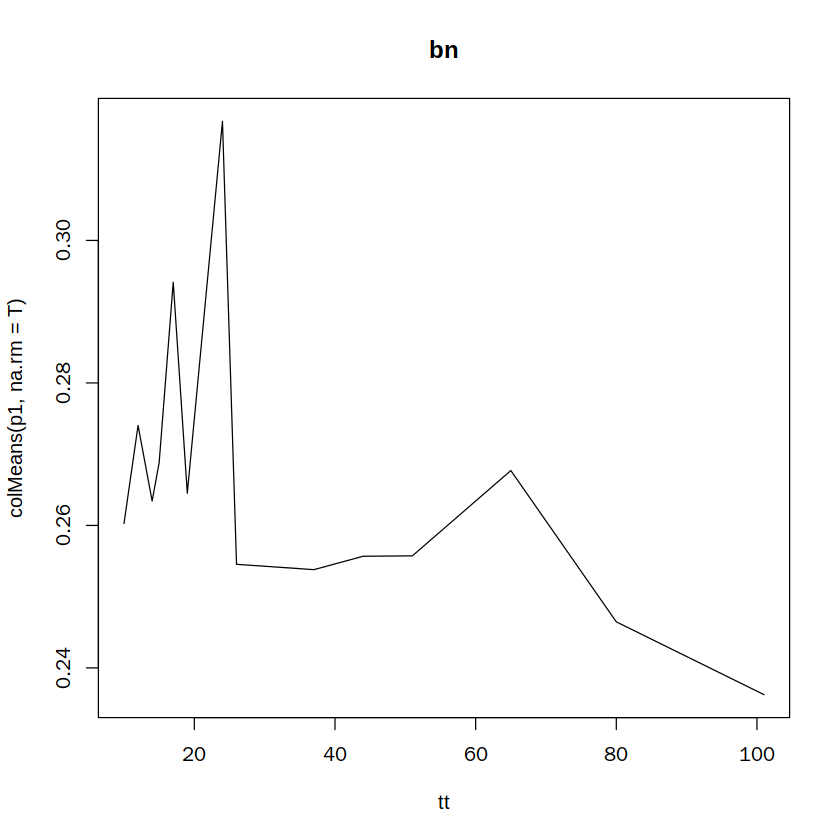

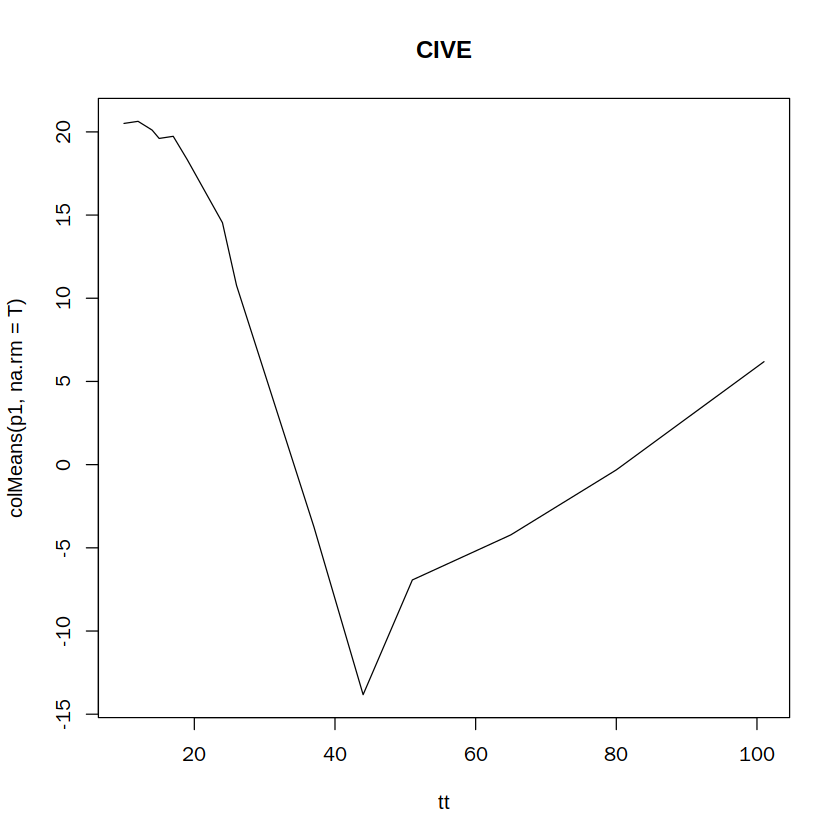

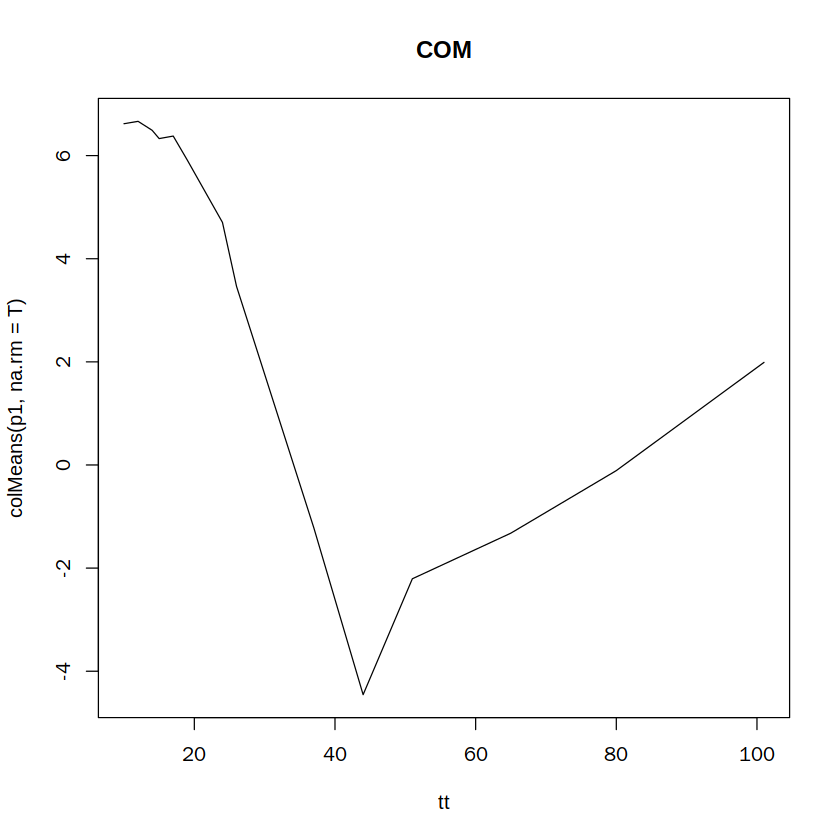

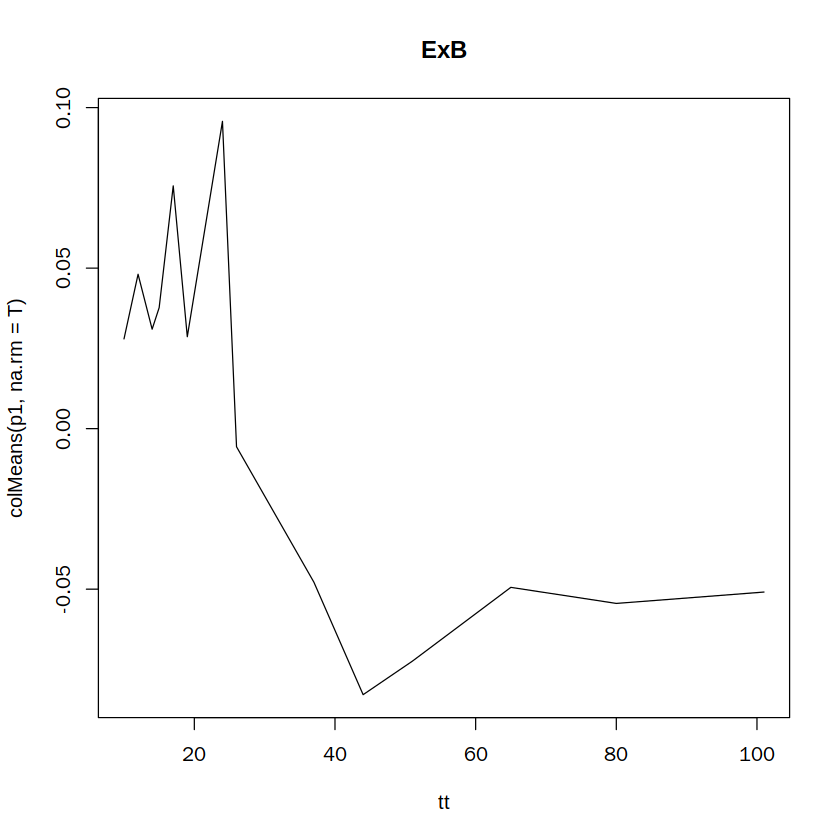

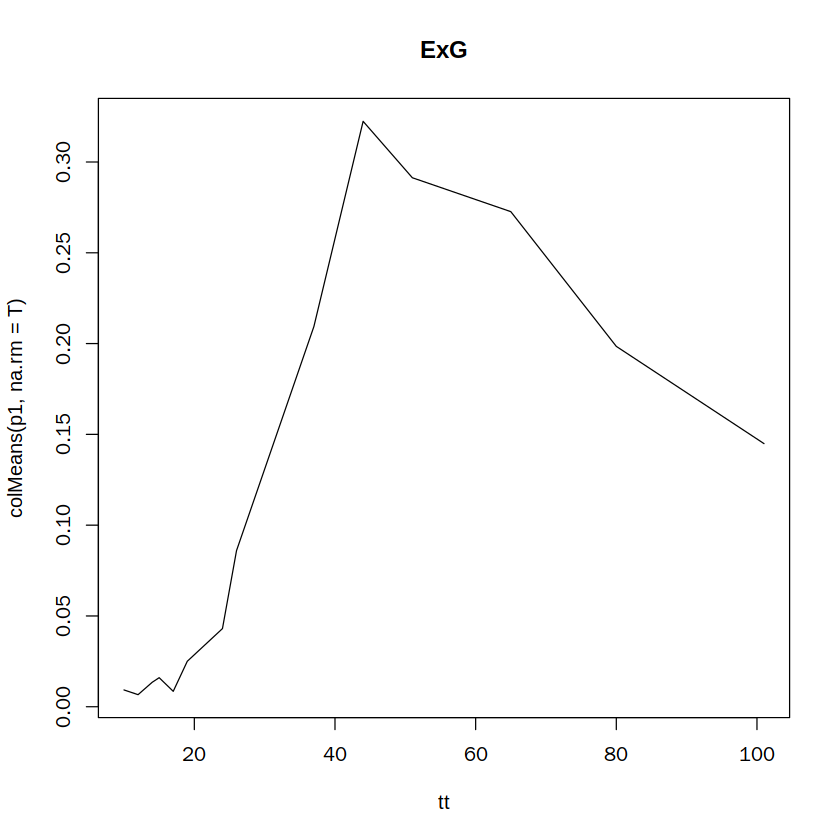

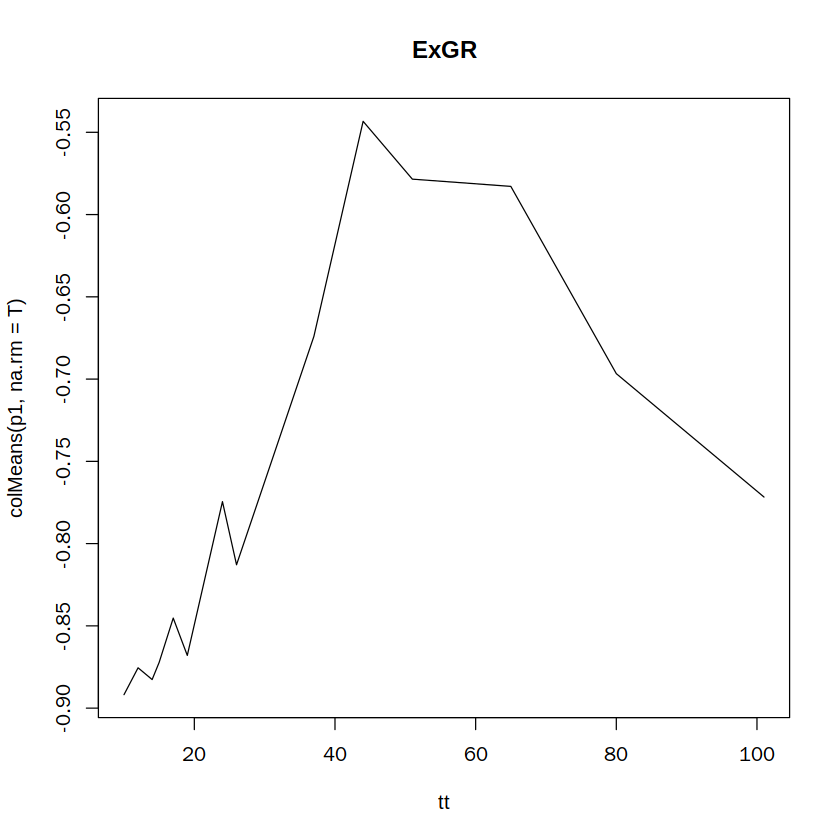

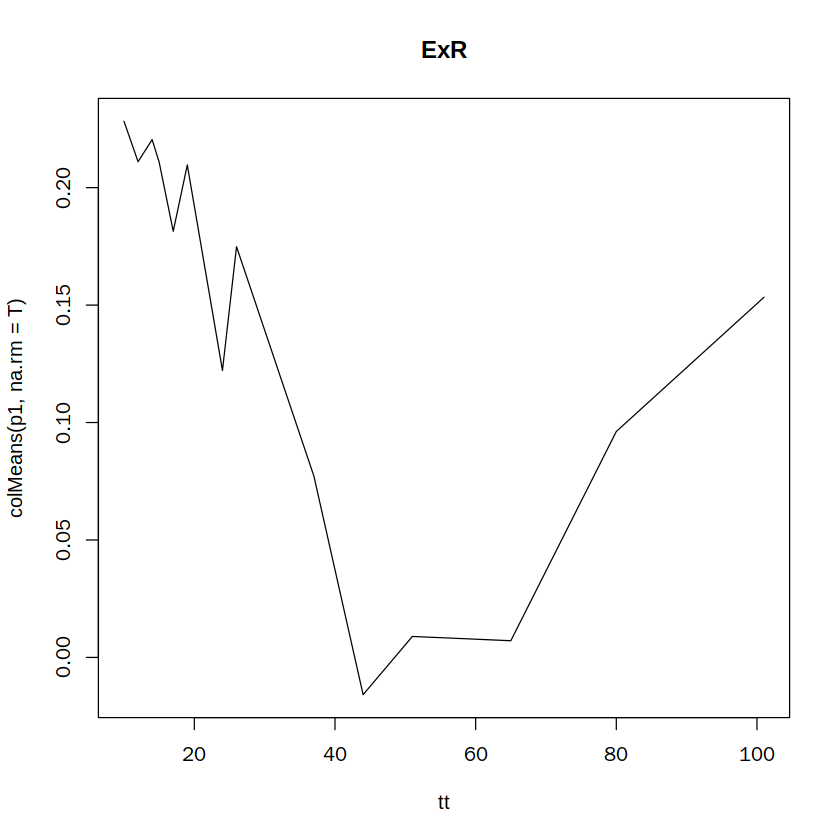

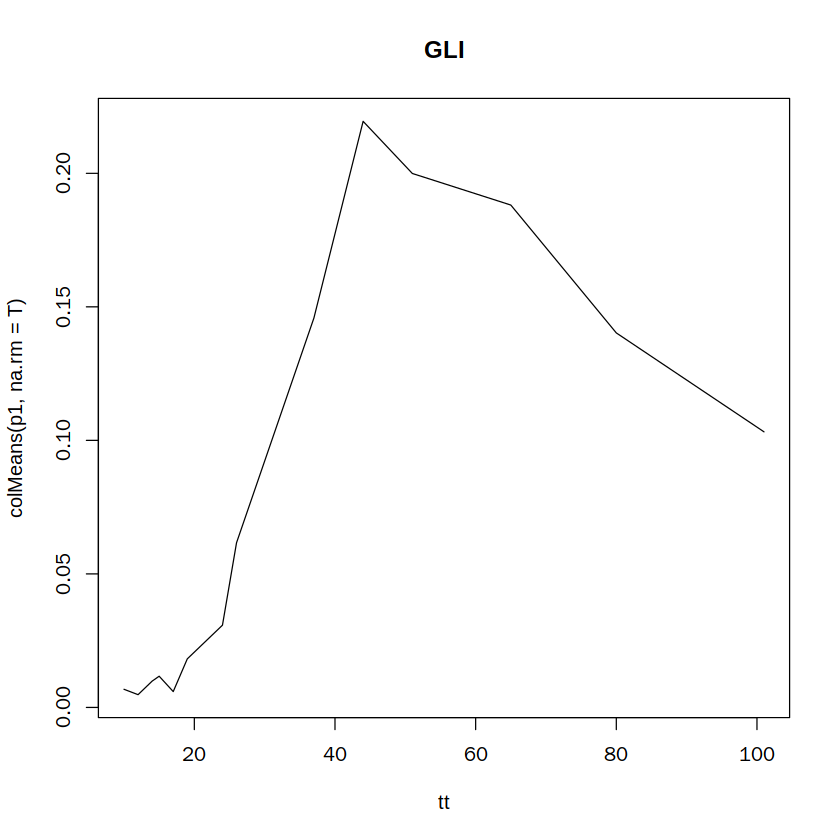

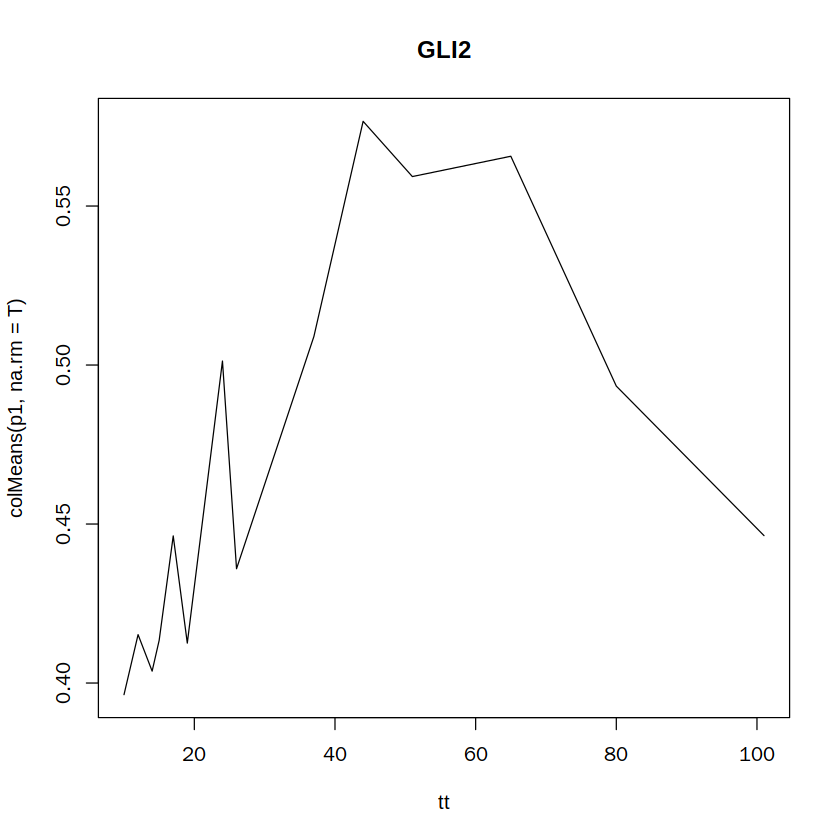

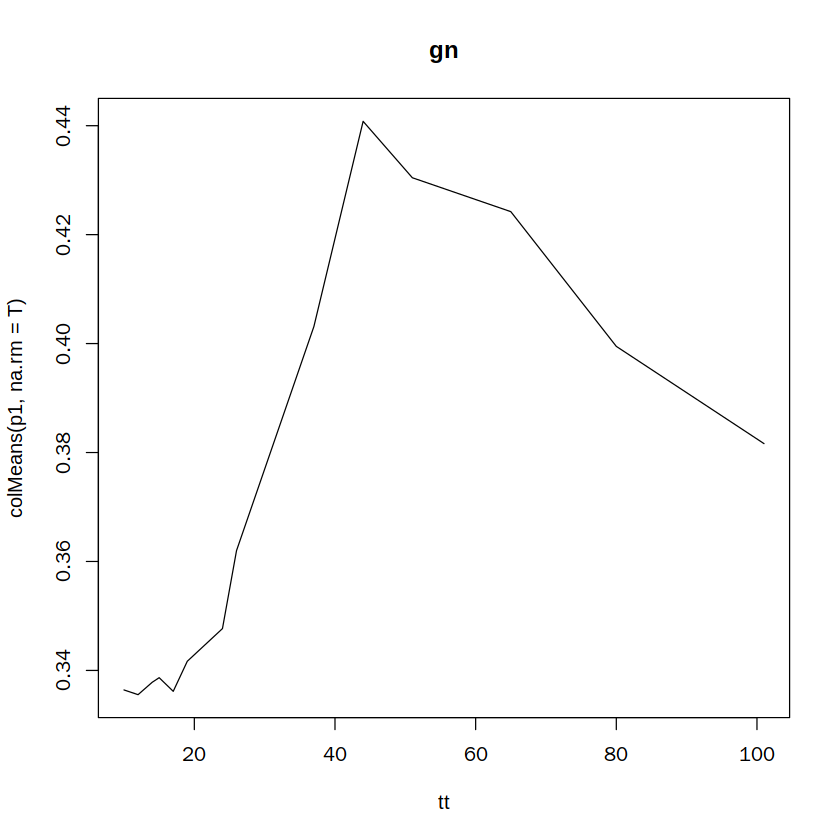

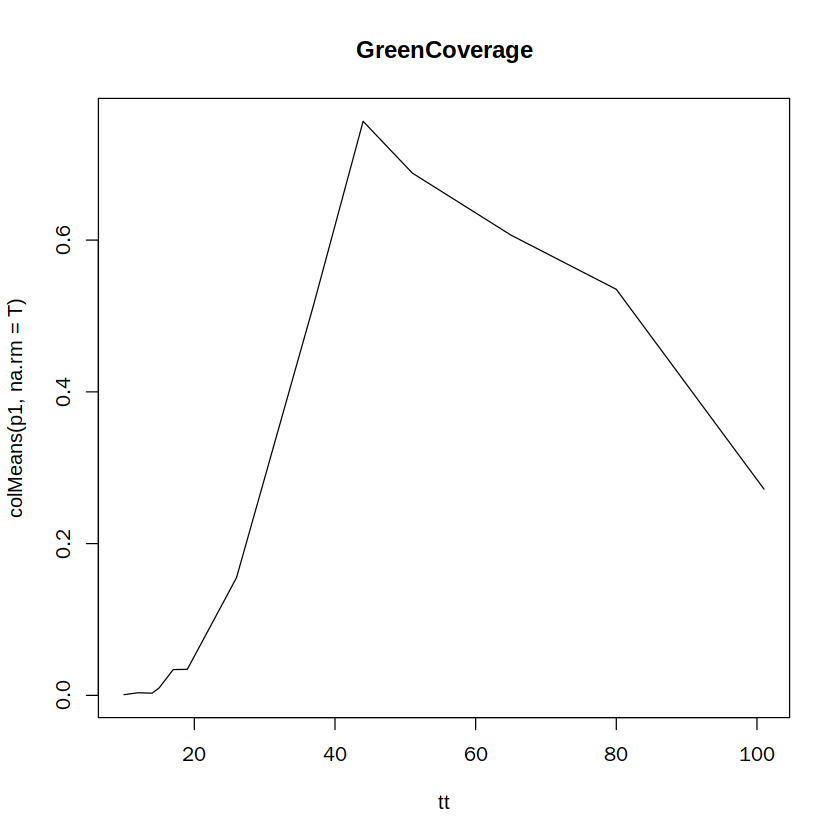

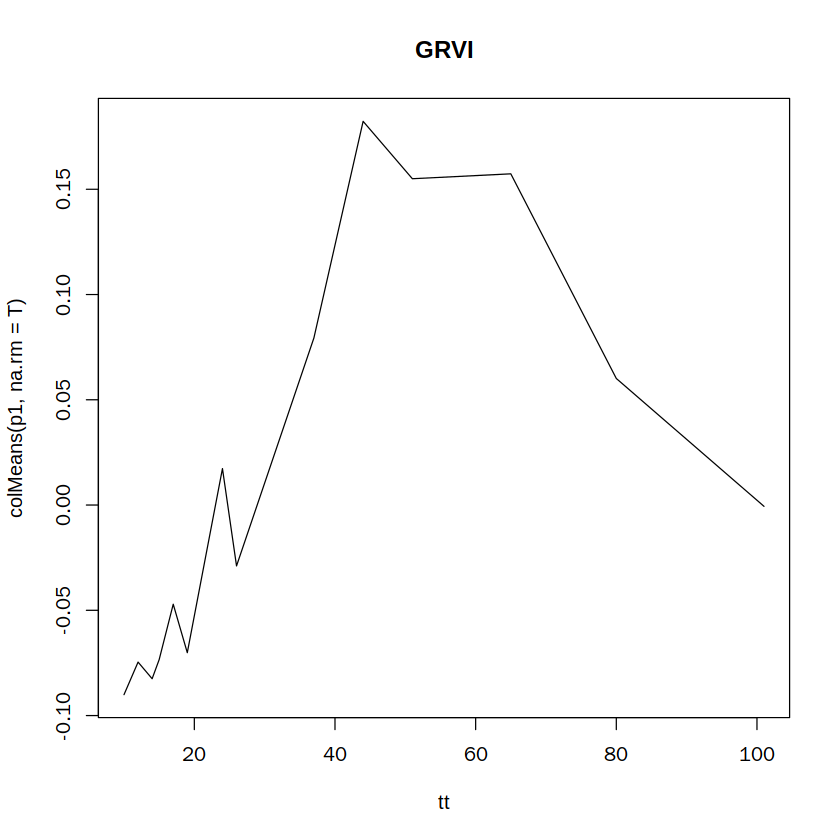

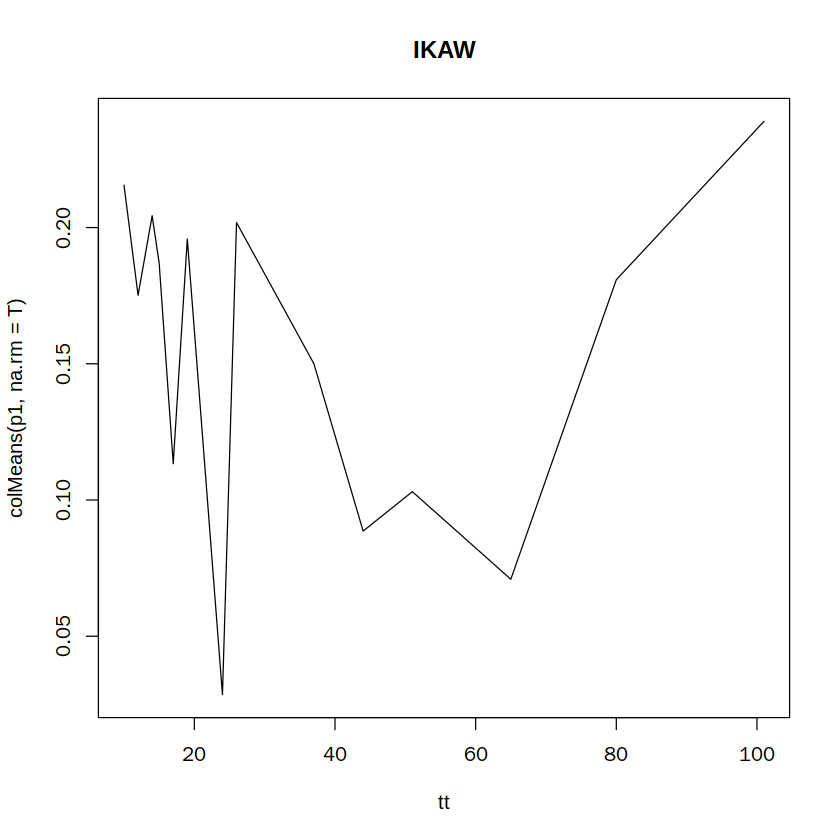

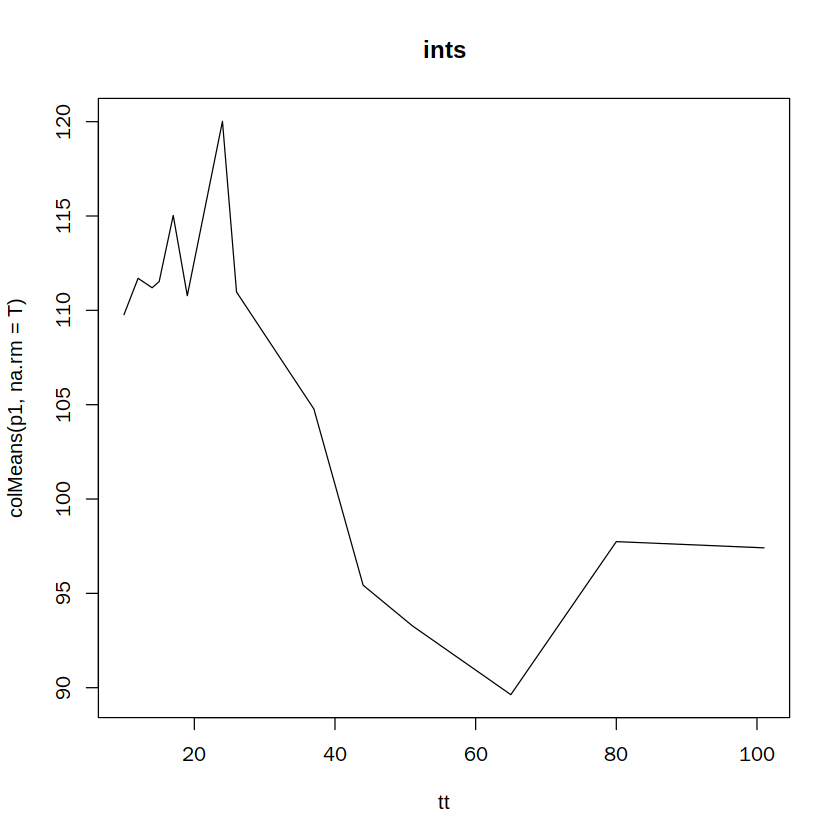

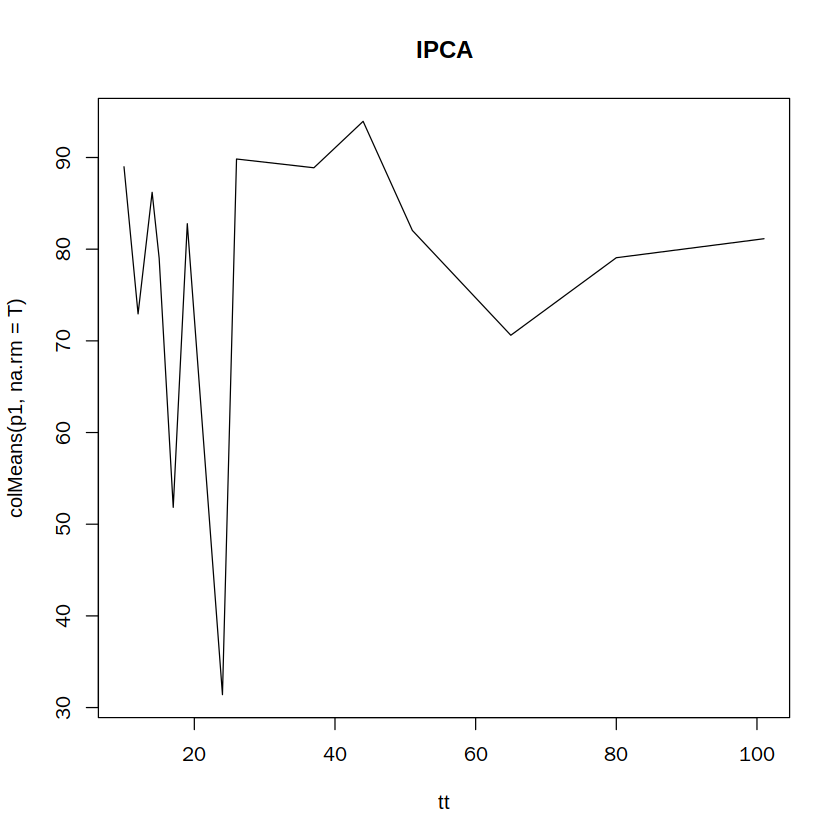

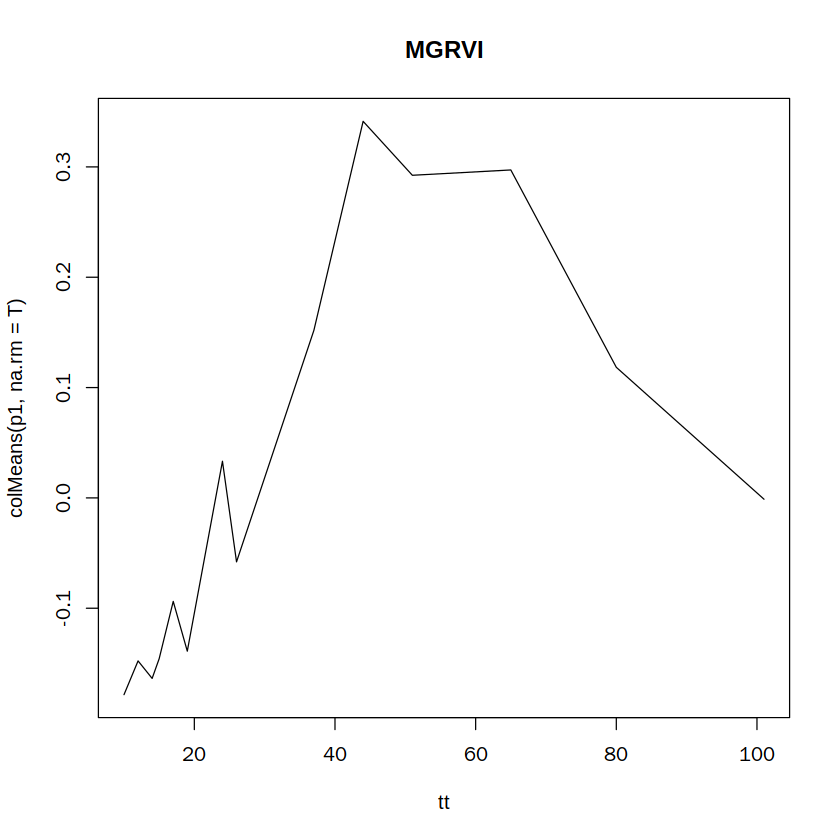

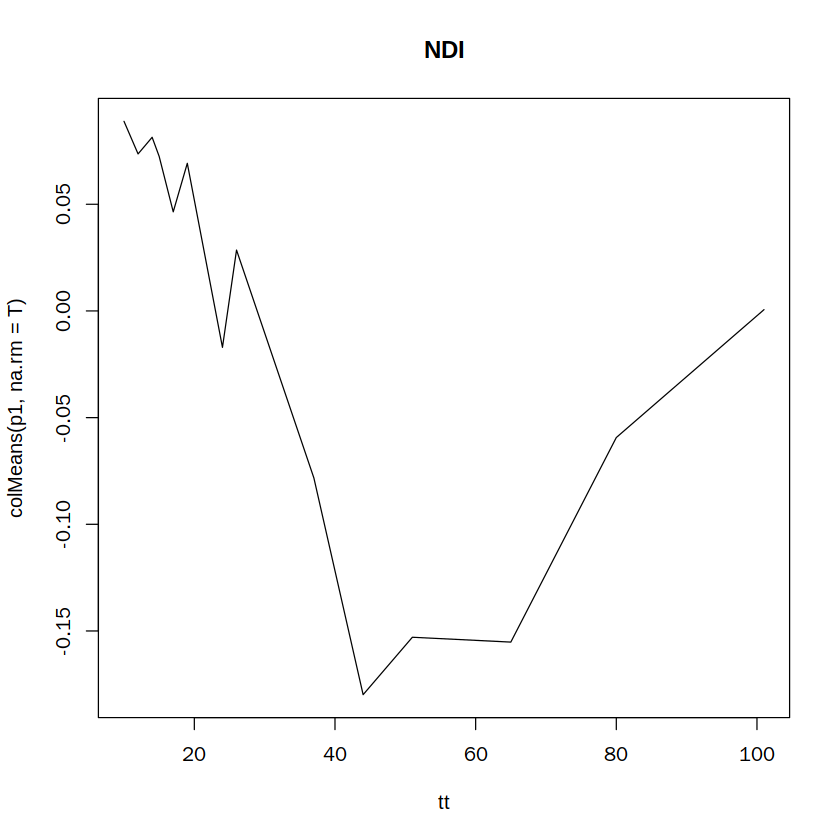

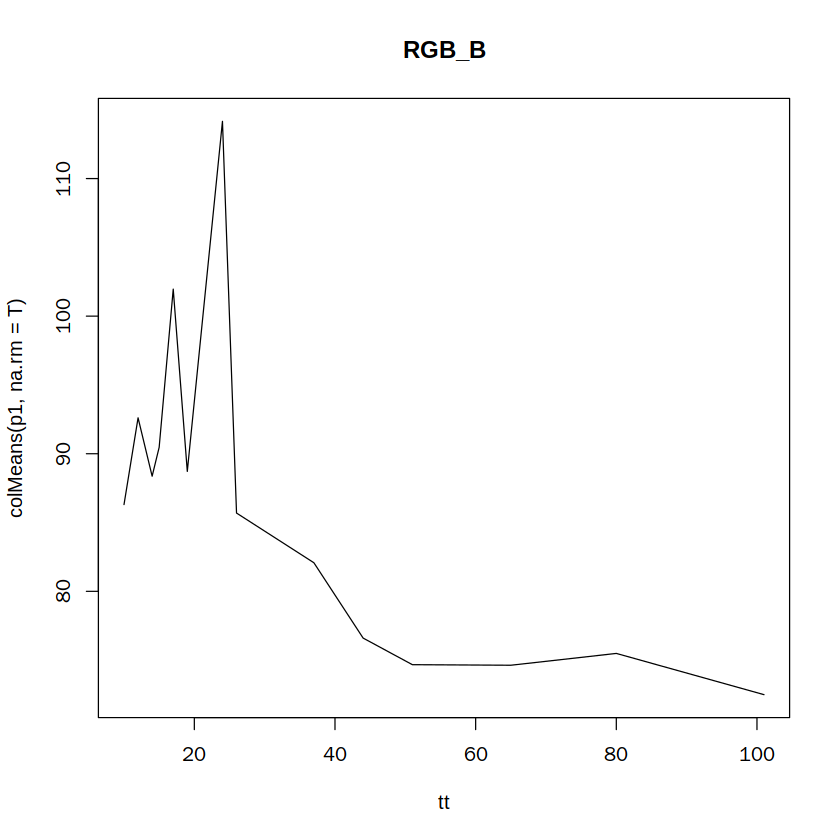

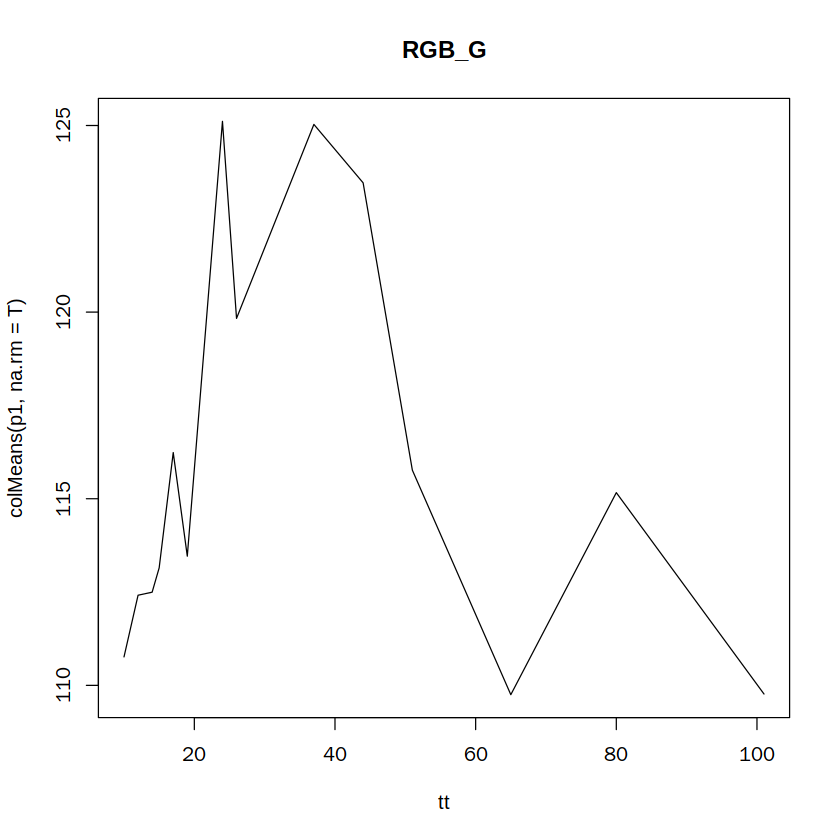

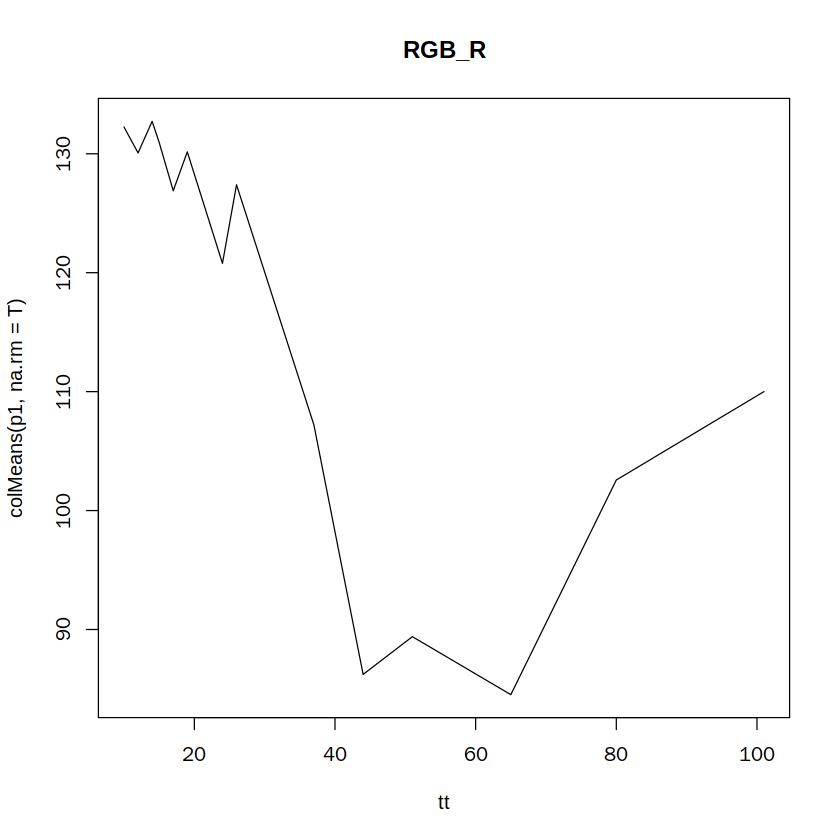

Warning message in fill_missing_values(p1):
“强制改变过程中产生了NA”
Warning message in fill_missing_values(p1):
“强制改变过程中产生了NA”
Warning message in fill_missing_values(p1):
“强制改变过程中产生了NA”
Warning message in fill_missing_values(p1):
“强制改变过程中产生了NA”
Warning message in fill_missing_values(p1):
“强制改变过程中产生了NA”
Warning message in fill_missing_values(p1):
“强制改变过程中产生了NA”
Warning message in fill_missing_values(p1):
“强制改变过程中产生了NA”
Warning message in fill_missing_values(p1):
“强制改变过程中产生了NA”


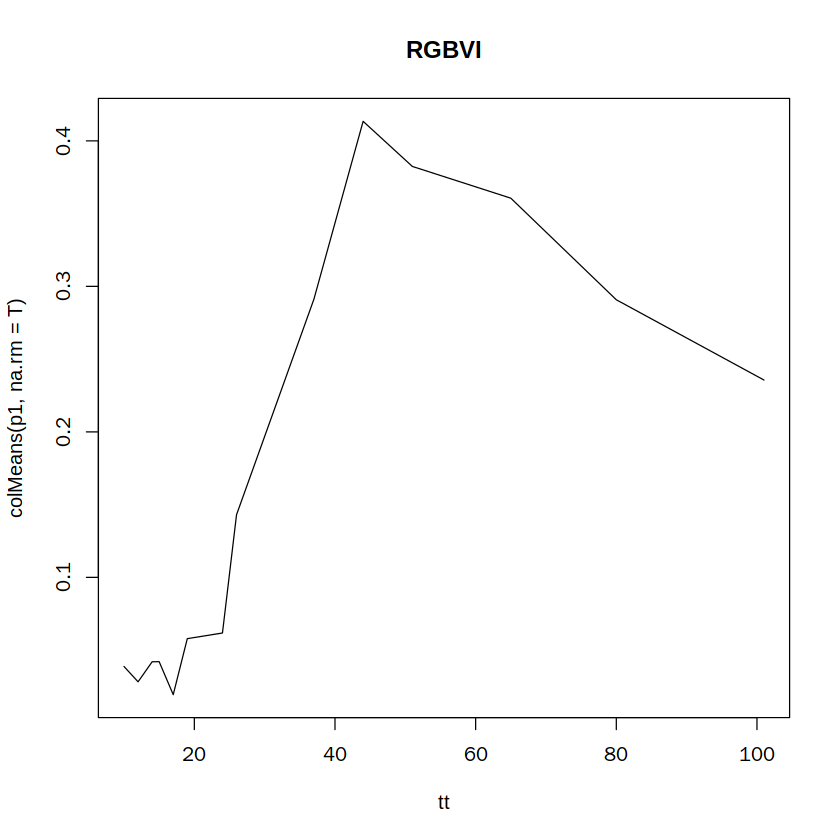

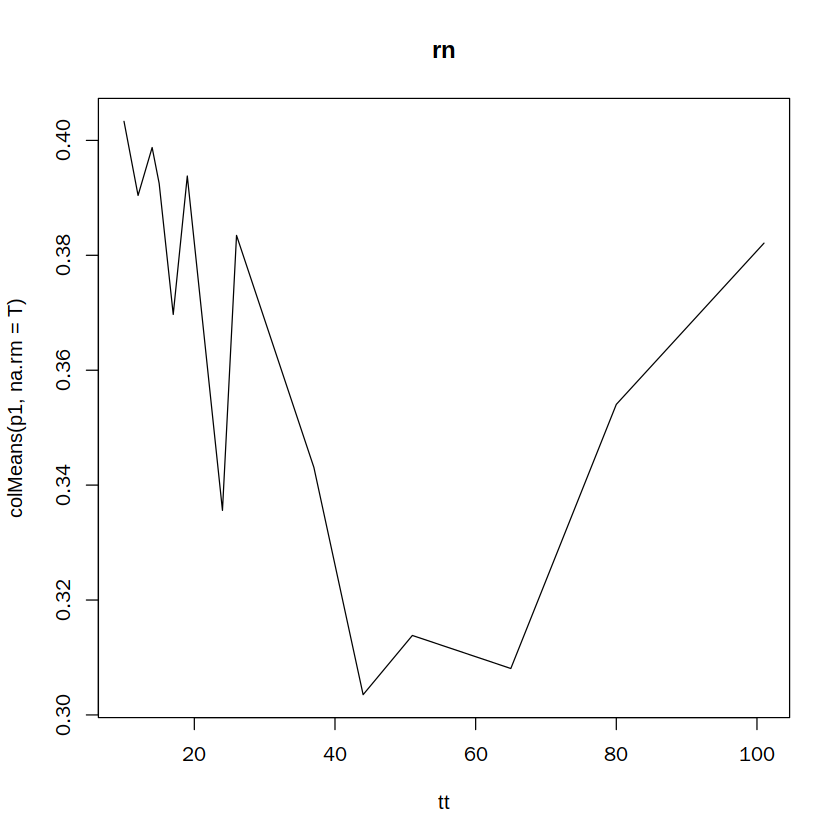

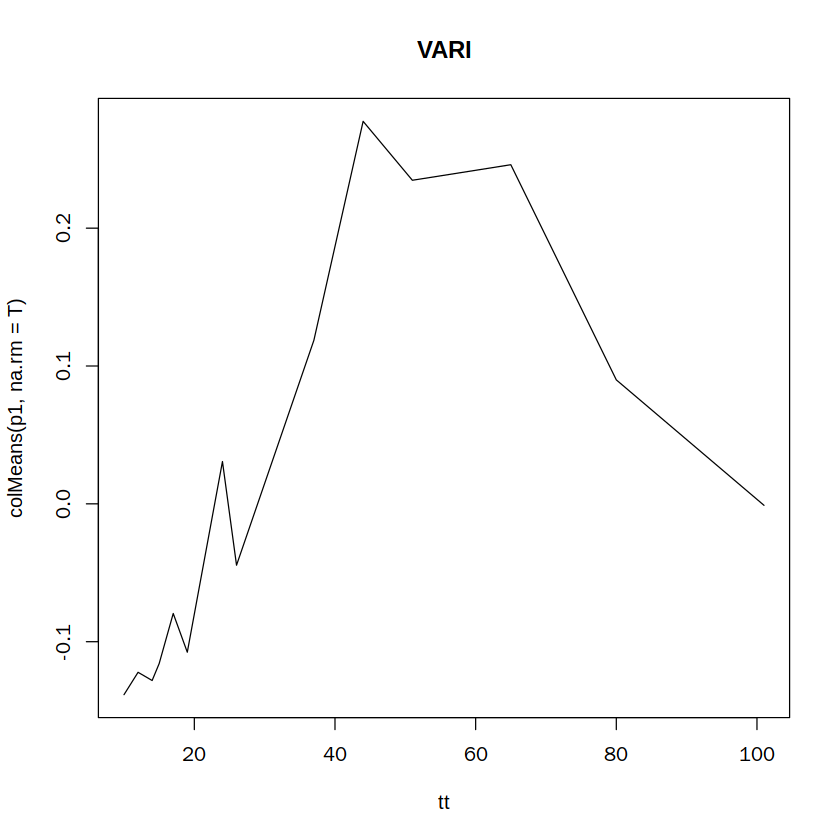

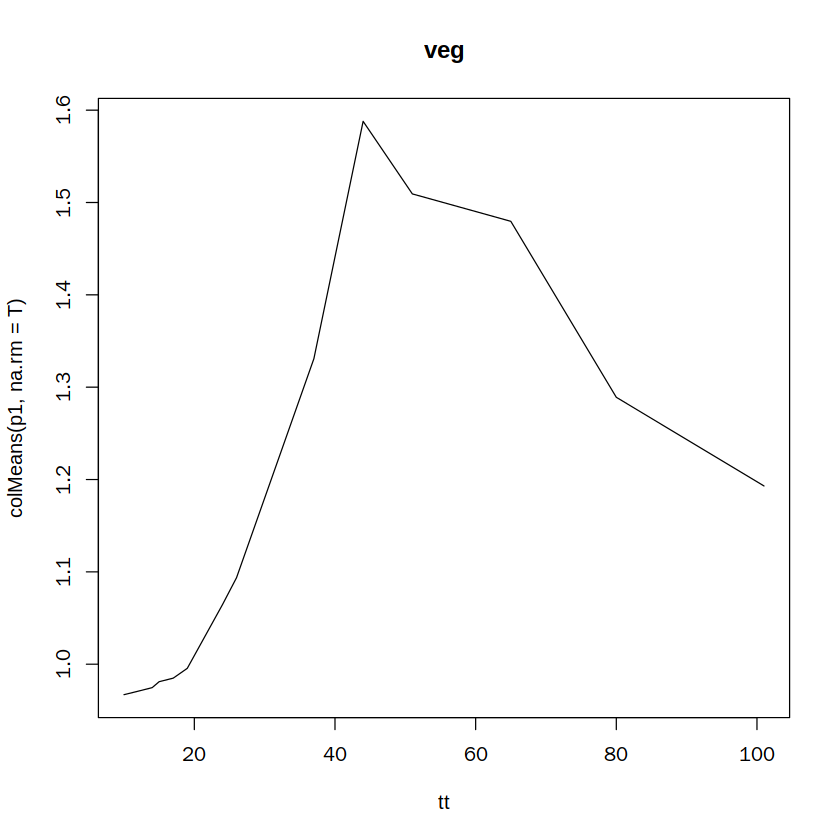

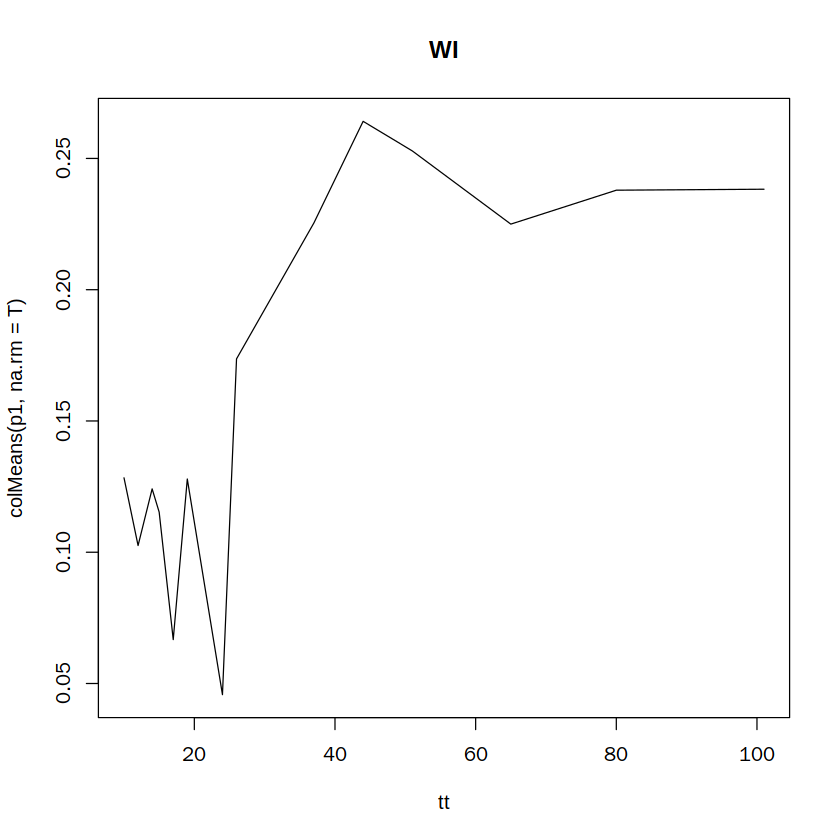

In [24]:
# 循环处理前25个表型数据并绘图
for(i in 1:25){
  # 提取第i个数据框
  p1 <- data_frames[[i]]
  
  # 填充该数据框中的缺失值
  p1 <- fill_missing_values(p1)
  
  # 绘制折线图
  # x轴：tt（从列名提取的数值）
  # y轴：每列的平均值（colMeans计算列均值，na.rm=T忽略NA值）
  # type="l" 指定为折线图
  # main=allpn[i] 设置图标题为当前数据框的名称
  plot(tt, colMeans(p1, na.rm=T), type="l", main=allpn[i])
}

In [25]:
# 关闭PDF设备，保存文件
dev.off()

pdf 
  3

In [32]:
ii <- c(2,3,5,6,7,8,9,10,11,12,13,14,16,17,20,21,22,23,24)

# 为每个选择的指标定义加法调整值
# 这些值可能用于数据标准化或校正
addv <- c(15,5,0,1,0,0,0,0,0,0.1,0,100,0.2,0.2,100,0,0,0.2,0)

# 为每个选择的指标定义符号/方向
# "+" 可能表示正相关，"/" 可能表示比值或特殊处理
signc <- c(rep("+",11),"/","+","+","/","+","+","+","+")
spn <- c("CIVE","COM","ExG","ExGR","ExR","GLI","GLI2","gn","GreenCoverage","GRVI","IKAW","ints",
         "MGRVI","NDI","RGB_R","RGBVI","rn","VARI","veg")

In [33]:
ii
addv
signc
spn

[1]  2  3  5  6  7  8  9 10 11 12 13 14 16 17 20 21 22 23 24

[1]  15.0   5.0   0.0   1.0   0.0   0.0   0.0   0.0   0.0   0.1   0.0 100.0
[13]   0.2   0.2 100.0   0.0   0.0   0.2   0.0

[1] "+" "+" "+" "+" "+" "+" "+" "+" "+" "+" "+" "/" "+" "+" "/" "+" "+" "+" "+"

[1] "CIVE"          "COM"           "ExG"           "ExGR"         
 [5] "ExR"           "GLI"           "GLI2"          "gn"           
 [9] "GreenCoverage" "GRVI"          "IKAW"          "ints"         
[13] "MGRVI"         "NDI"           "RGB_R"         "RGBVI"        
[17] "rn"            "VARI"          "veg"

In [34]:
pheno_select <- list(si=ii, addv=addv, signc=signc, spn=spn)
pheno_select

$si
 [1]  2  3  5  6  7  8  9 10 11 12 13 14 16 17 20 21 22 23 24

$addv
 [1]  15.0   5.0   0.0   1.0   0.0   0.0   0.0   0.0   0.0   0.1   0.0 100.0
[13]   0.2   0.2 100.0   0.0   0.0   0.2   0.0

$signc
 [1] "+" "+" "+" "+" "+" "+" "+" "+" "+" "+" "+" "/" "+" "+" "/" "+" "+" "+" "+"

$spn
 [1] "CIVE"          "COM"           "ExG"           "ExGR"         
 [5] "ExR"           "GLI"           "GLI2"          "gn"           
 [9] "GreenCoverage" "GRVI"          "IKAW"          "ints"         
[13] "MGRVI"         "NDI"           "RGB_R"         "RGBVI"        
[17] "rn"            "VARI"          "veg"